# Machine Translation: Concepts, Models, and Metrics

This notebook covers:

1. **6 concepts**: neural machine translation, image OCR translation, transliteration, language identification, back-translation, pivot translation
2. **2 models + Google Translate reference**: Helsinki-NLP OPUS-MT (MarianMT), Facebook mBART-50 (many-to-many), and Google Translate as a commercial benchmark
3. **6 performance metrics**: BLEU, chrF, METEOR, TER, WER, BERTScore

Language pair used for demos: English ↔ Hindi. Run all cells in order.


## 0. Setup

Install the required libraries. This may take 2–3 minutes on first run.

In [ ]:
!pip install -q transformers sentencepiece sacremoses
!pip install -q sacrebleu nltk langdetect
!pip install -q pytesseract Pillow requests
!pip install -q indic-transliteration
!pip install -q jiwer bert-score
!pip install -q deep-translator
!apt-get -qq install -y tesseract-ocr tesseract-ocr-hin > /dev/null


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 867.8/867.8 kB 12.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 13.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.0/129.0 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.9/162.9 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 41.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 kB 2.3 MB/s eta 0:00:00


In [ ]:
import nltk
import matplotlib.pyplot as plt
nltk.download('wordnet')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('omw-1.4')
print("Setup complete.")


[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Setup complete.


## Concept 1: Neural Machine Translation (text-to-text)

Neural machine translation (NMT) converts text from a source language to a target language using
a trained neural network. We load a pretrained MarianMT model from Helsinki-NLP.


In [ ]:
from transformers import MarianMTModel, MarianTokenizer

MODEL_A_NAME = "Helsinki-NLP/opus-mt-en-hi"

tokenizer_a = MarianTokenizer.from_pretrained(MODEL_A_NAME)
model_a = MarianMTModel.from_pretrained(MODEL_A_NAME)

def translate_marian(texts, tokenizer=tokenizer_a, model=model_a):
    batch = tokenizer(texts, return_tensors="pt", padding=True)
    generated = model.generate(**batch)
    return [tokenizer.decode(t, skip_special_tokens=True) for t in generated]

sample_sentences = [
    "The weather is nice today.",
    "I am learning machine translation.",
    "Please send me the report by tomorrow."
]

translations = translate_marian(sample_sentences)
for src, tgt in zip(sample_sentences, translations):
    print(f"EN: {src}\nHI: {tgt}\n")


tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/812k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/1.07M [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  306MB            

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

EN: The weather is nice today.
HI: मौसम आज अच्छा है.

EN: I am learning machine translation.
HI: मैं मशीन अनुवाद सीख रहा हूँ.

EN: Please send me the report by tomorrow.
HI: कृपया मुझे कल से रिपोर्ट भेजें.



## Concept 2: Image OCR Translation

Image OCR translation extracts text from an image using optical character recognition (OCR),
then passes that text through the NMT model. Pipeline: **image → OCR text → translated text**.

The image is fetched from the internet by URL. Swap `IMAGE_URL` for any image containing
English text — a sign, a scanned page, a screenshot.


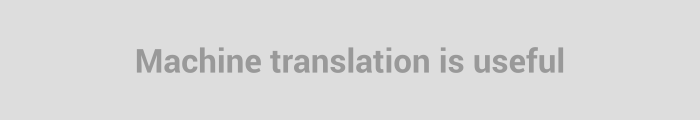

OCR extracted text: Machine translation is useful
Translated text: मशीन अनुवाद उपयोगी है


In [ ]:
import requests
from io import BytesIO
from PIL import Image
import pytesseract

# Any direct image URL with clear English text works here.
IMAGE_URL = "https://placehold.co/700x120/png?text=Machine+translation+is+useful&font=roboto"

def fetch_image(url):
    response = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=15)
    response.raise_for_status()
    return Image.open(BytesIO(response.content)).convert("RGB")

# Option A: use your own uploaded image instead (uncomment in Colab)
# from google.colab import files
# uploaded = files.upload()
# img = Image.open(list(uploaded.keys())[0])

# Option B: fetch the image above from the internet
img = fetch_image(IMAGE_URL)

display(img)

ocr_text = pytesseract.image_to_string(img).strip()
print("OCR extracted text:", ocr_text)

if ocr_text:
    ocr_translation = translate_marian([ocr_text])[0]
    print("Translated text:", ocr_translation)


## Concept 3: Transliteration

Transliteration converts text from one script to another while keeping the pronunciation,
without changing the language. Example: Devanagari script → Latin script (romanization),
and back. This differs from translation, which changes meaning across languages.


In [ ]:
from indic_transliteration import sanscript
from indic_transliteration.sanscript import transliterate

devanagari_text = "नमस्ते, आप कैसे हैं?"

# Devanagari -> Latin (IAST romanization)
latin_text = transliterate(devanagari_text, sanscript.DEVANAGARI, sanscript.IAST)
print("Devanagari:", devanagari_text)
print("Latin (IAST):", latin_text)

# Latin (ITRANS style) -> Devanagari
itrans_text = "namaste, aap kaise hain?"
back_to_devanagari = transliterate(itrans_text, sanscript.ITRANS, sanscript.DEVANAGARI)
print("\nITRANS:", itrans_text)
print("Devanagari:", back_to_devanagari)


Devanagari: नमस्ते, आप कैसे हैं?
Latin (IAST): namaste, āpa kaise haiṃ?

ITRANS: namaste, aap kaise hain?
Devanagari: नमस्ते, आप् कैसे हैन्?


## Concept 4: Language Identification

Language identification detects the source language of a text before translation.
This step matters in real pipelines, where the input language is not known in advance.


In [ ]:
from langdetect import detect, detect_langs

test_texts = [
    "The weather is nice today.",
    "नमस्ते, आप कैसे हैं?",
    "Bonjour, comment ça va?",
    "Hola, ¿cómo estás?"
]

for text in test_texts:
    lang = detect(text)
    probs = detect_langs(text)
    print(f"Text: {text}\nDetected: {lang}  |  Probabilities: {probs}\n")


Text: The weather is nice today.
Detected: en  |  Probabilities: [en:0.9999972602270712]

Text: नमस्ते, आप कैसे हैं?
Detected: hi  |  Probabilities: [hi:0.9999992628145457]

Text: Bonjour, comment ça va?
Detected: fr  |  Probabilities: [fr:0.7142846333202623, ca:0.28571522356174667]

Text: Hola, ¿cómo estás?
Detected: es  |  Probabilities: [es:0.9999971979124295]



## Concept 5: Back-Translation

Back-translation translates a sentence into the target language, then translates that
result back into the source language. Comparing the round-trip output with the original
sentence is a quick, reference-free way to sanity-check translation quality.


In [ ]:
tokenizer_hi_en = MarianTokenizer.from_pretrained("Helsinki-NLP/opus-mt-hi-en")
model_hi_en = MarianMTModel.from_pretrained("Helsinki-NLP/opus-mt-hi-en")

def translate_hi_to_en(texts):
    batch = tokenizer_hi_en(texts, return_tensors="pt", padding=True)
    generated = model_hi_en.generate(**batch)
    return [tokenizer_hi_en.decode(t, skip_special_tokens=True) for t in generated]

original = ["Please send me the report by tomorrow."]
forward = translate_marian(original)          # EN -> HI
round_trip = translate_hi_to_en(forward)       # HI -> EN

print("Original:    ", original[0])
print("EN -> HI:    ", forward[0])
print("HI -> EN:    ", round_trip[0])
print("\nRound-trip closely matches the original -> good sign for translation quality.")


tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/813k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.06M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.38k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  304MB            

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Original:     Please send me the report by tomorrow.
EN -> HI:     कृपया मुझे कल से रिपोर्ट भेजें.
HI -> EN:     Please send me a report from tomorrow.

Round-trip closely matches the original -> good sign for translation quality.


## Concept 6: Pivot Translation

Pivot translation routes a translation through an intermediate ("pivot") language when
no direct model exists for the source-target pair. Example: Hindi → French, routed
through English as the pivot (Hindi → English → French).


In [ ]:
# Step 1: Hindi -> English (pivot)
hindi_text = ["कृपया मुझे कल तक रिपोर्ट भेजें।"]
pivot_english = translate_hi_to_en(hindi_text)

# Step 2: English -> French
tokenizer_en_fr = MarianTokenizer.from_pretrained("Helsinki-NLP/opus-mt-en-fr")
model_en_fr = MarianMTModel.from_pretrained("Helsinki-NLP/opus-mt-en-fr")

def translate_en_to_fr(texts):
    batch = tokenizer_en_fr(texts, return_tensors="pt", padding=True)
    generated = model_en_fr.generate(**batch)
    return [tokenizer_en_fr.decode(t, skip_special_tokens=True) for t in generated]

final_french = translate_en_to_fr(pivot_english)

print("Hindi:          ", hindi_text[0])
print("Pivot (English):", pivot_english[0])
print("French:         ", final_french[0])


tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.34M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  301MB            

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Hindi:           कृपया मुझे कल तक रिपोर्ट भेजें।
Pivot (English): Please send me a report by tomorrow.
French:          Envoyez-moi un rapport d'ici demain.


## Model Comparison: MarianMT vs mBART-50

**Model A — Helsinki-NLP/opus-mt-en-hi (MarianMT)**
A bilingual model trained specifically for English→Hindi. Small and fast.

**Model B — facebook/mbart-large-50-many-to-many-mmt (mBART-50)**
A large multilingual model that supports 50 languages in a single model, including English→Hindi.

Both models translate the same test set below, for comparison.


In [ ]:
from transformers import MBartForConditionalGeneration, MBart50TokenizerFast

MODEL_B_NAME = "facebook/mbart-large-50-many-to-many-mmt"

tokenizer_b = MBart50TokenizerFast.from_pretrained(MODEL_B_NAME)
model_b = MBartForConditionalGeneration.from_pretrained(MODEL_B_NAME)
tokenizer_b.src_lang = "en_XX"

def translate_mbart(texts, tokenizer=tokenizer_b, model=model_b, target_lang="hi_IN"):
    batch = tokenizer(texts, return_tensors="pt", padding=True)
    generated = model.generate(
        **batch,
        forced_bos_token_id=tokenizer.lang_code_to_id[target_lang]
    )
    return [tokenizer.decode(t, skip_special_tokens=True) for t in generated]

test_source = [
    "The weather is nice today.",
    "I am learning machine translation.",
    "Please send me the report by tomorrow.",
    "This city has a long history.",
    "Can you help me with this task?"
]

# Reference (human) translations, used later for metric scoring
test_reference = [
    "आज मौसम अच्छा है।",
    "मैं मशीन अनुवाद सीख रहा हूँ।",
    "कृपया मुझे कल तक रिपोर्ट भेजें।",
    "इस शहर का एक लंबा इतिहास है।",
    "क्या आप इस काम में मेरी मदद कर सकते हैं?"
]

output_a = translate_marian(test_source)
output_b = translate_mbart(test_source)

for i, src in enumerate(test_source):
    print(f"SRC: {src}")
    print(f"Model A (MarianMT): {output_a[i]}")
    print(f"Model B (mBART-50): {output_b[i]}")
    print(f"Reference:          {test_reference[i]}\n")


tokenizer_config.json:   0%|          | 0.00/529 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/649 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.44GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/516 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/261 [00:00<?, ?B/s]

SRC: The weather is nice today.
Model A (MarianMT): मौसम आज अच्छा है.
Model B (mBART-50): आज मौसम अच्छा है।
Reference:          आज मौसम अच्छा है।

SRC: I am learning machine translation.
Model A (MarianMT): मैं मशीन अनुवाद सीख रहा हूँ.
Model B (mBART-50): मैं मशीन अनुवाद सीख रहा हूँ।
Reference:          मैं मशीन अनुवाद सीख रहा हूँ।

SRC: Please send me the report by tomorrow.
Model A (MarianMT): कृपया मुझे कल से रिपोर्ट भेजें.
Model B (mBART-50): कृपया मुझे कल तक रिपोर्ट भेजें।
Reference:          कृपया मुझे कल तक रिपोर्ट भेजें।

SRC: This city has a long history.
Model A (MarianMT): इस शहर का एक लंबा इतिहास है.
Model B (mBART-50): इस शहर का इतिहास बहुत पुराना है।
Reference:          इस शहर का एक लंबा इतिहास है।

SRC: Can you help me with this task?
Model A (MarianMT): आप इस कार्य के साथ मेरी मदद कर सकते हैं?
Model B (mBART-50): क्या आप इस कार्य में मेरी मदद कर सकते हैं?
Reference:          क्या आप इस काम में मेरी मदद कर सकते हैं?



### Bonus: Google Translate

Google Translate is a production commercial system, not a model you load yourself — it's
included here as a real-world reference point alongside the two open models above.
`deep-translator` calls Google's public translation endpoint, no API key needed.

This endpoint rate-limits aggressively, especially from shared Colab IPs. The cell below
retries a fixed number of times with a flat delay, then falls back to MyMemory (a
different free engine) if Google keeps refusing.


In [ ]:
import time
from deep_translator import GoogleTranslator, MyMemoryTranslator

def translate_google(texts, source="en", target="hi", delay=2.0, max_retries=3):
    # MyMemory needs locale-style codes (en-US, hi-IN), not bare "en"/"hi"
    fallback_locales = {"en": "en-US", "hi": "hi-IN"}
    fallback_source = fallback_locales.get(source, source)
    fallback_target = fallback_locales.get(target, target)

    translator = GoogleTranslator(source=source, target=target)
    fallback = MyMemoryTranslator(source=fallback_source, target=fallback_target)  # used only if Google fails
    results = []

    for t in texts:
        translated = None

        for attempt in range(max_retries):
            try:
                translated = translator.translate(t)
                break
            except Exception as e:
                print(f"Google Translate error ({e}); retrying in {delay}s...")
                time.sleep(delay)

        if translated is None:
            print(f"Giving up on Google Translate for: {t!r} -- falling back to MyMemory.")
            try:
                translated = fallback.translate(t)
            except Exception as e:
                translated = "[translation failed]"

        results.append(translated)
        time.sleep(delay)  # space out requests even on success

    return results

output_c = translate_google(test_source)

for i, src in enumerate(test_source):
    print(f"SRC: {src}")
    print(f"Google Translate: {output_c[i]}")
    print(f"Reference:        {test_reference[i]}\n")


Google Translate error (Server Error: You made too many requests to the server.According to google, you are allowed to make 5 requests per secondand up to 200k requests per day. You can wait and try again later oryou can try the translate_batch function); retrying in 2.0s...
Google Translate error (Server Error: You made too many requests to the server.According to google, you are allowed to make 5 requests per secondand up to 200k requests per day. You can wait and try again later oryou can try the translate_batch function); retrying in 2.0s...
Google Translate error (Server Error: You made too many requests to the server.According to google, you are allowed to make 5 requests per secondand up to 200k requests per day. You can wait and try again later oryou can try the translate_batch function); retrying in 2.0s...
Giving up on Google Translate for: 'The weather is nice today.' -- falling back to MyMemory.
Google Translate error (Server Error: You made too many requests to the server.

## Performance Metrics

Six metrics score translation quality against the human reference translations:

| Metric | Measures | Range |
|---|---|---|
| **BLEU** | n-gram precision overlap | 0–100, higher is better |
| **chrF** | character n-gram F-score | 0–100, higher is better |
| **METEOR** | precision, recall, and synonym/stem matching | 0–1, higher is better |
| **TER** | edit distance to reach the reference | 0+, lower is better |
| **WER** | word-level edit distance | 0+, lower is better |
| **BERTScore** | semantic similarity via contextual embeddings | 0–1, higher is better |


In [ ]:
import sacrebleu
import jiwer
from bert_score import score as bert_score
from nltk.translate.meteor_score import meteor_score
from nltk.tokenize import word_tokenize

def score_bleu(hyps, refs):
    return sacrebleu.corpus_bleu(hyps, [refs]).score

def score_chrf(hyps, refs):
    return sacrebleu.corpus_chrf(hyps, [refs]).score

def score_ter(hyps, refs):
    return sacrebleu.corpus_ter(hyps, [refs]).score

def score_meteor(hyps, refs):
    scores = [
        meteor_score([word_tokenize(ref)], word_tokenize(hyp))
        for hyp, ref in zip(hyps, refs)
    ]
    return sum(scores) / len(scores)

def score_wer(hyps, refs):
    return jiwer.wer(refs, hyps)

def score_bertscore(hyps, refs, lang="hi"):
    P, R, F1 = bert_score(hyps, refs, lang=lang, verbose=False)
    return F1.mean().item()

results = {}
for name, hyps in [
    ("Model A (MarianMT)", output_a),
    ("Model B (mBART-50)", output_b),
    ("Google Translate", output_c),
]:
    results[name] = {
        "BLEU": round(score_bleu(hyps, test_reference), 2),
        "chrF": round(score_chrf(hyps, test_reference), 2),
        "METEOR": round(score_meteor(hyps, test_reference), 4),
        "TER": round(score_ter(hyps, test_reference), 2),
        "WER": round(score_wer(hyps, test_reference), 4),
        "BERTScore": round(score_bertscore(hyps, test_reference), 4),
    }

results


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{'Model A (MarianMT)': {'BLEU': 47.88,
  'chrF': 78.21,
  'METEOR': 0.6723,
  'TER': 30.3,
  'WER': 0.3333,
  'BERTScore': 0.968},
 'Model B (mBART-50)': {'BLEU': 73.79,
  'chrF': 86.14,
  'METEOR': 0.906,
  'TER': 12.12,
  'WER': 0.1212,
  'BERTScore': 0.9754},
 'Google Translate': {'BLEU': 74.74,
  'chrF': 82.43,
  'METEOR': 0.7557,
  'TER': 21.21,
  'WER': 0.2121,
  'BERTScore': 0.9105}}

In [ ]:
import pandas as pd

df = pd.DataFrame(results).T
df.index.name = "Model"
df


,BLEU,chrF,METEOR,TER,WER,BERTScore
Model,,,,,,
Model A (MarianMT),47.88,78.21,0.6723,30.30,0.3333,0.9680
Model B (mBART-50),73.79,86.14,0.9060,12.12,0.1212,0.9754
Google Translate,74.74,82.43,0.7557,21.21,0.2121,0.9105


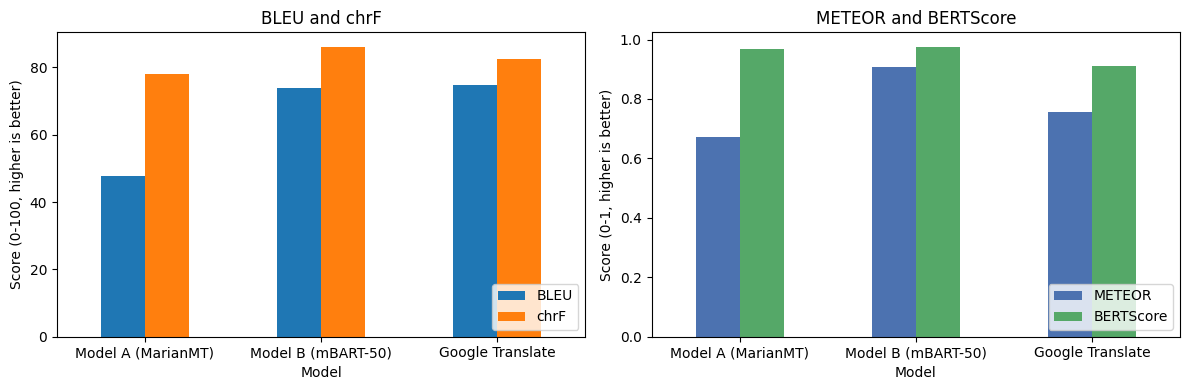

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df[["BLEU", "chrF"]].plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_ylabel("Score (0-100, higher is better)")
axes[0].set_title("BLEU and chrF")
axes[0].legend(loc="lower right")

df[["METEOR", "BERTScore"]].plot(kind="bar", ax=axes[1], rot=0, color=["#4c72b0", "#55a868"])
axes[1].set_ylabel("Score (0-1, higher is better)")
axes[1].set_title("METEOR and BERTScore")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


### Extra: Inference Speed

Translation quality is one axis. Speed is another, and it matters for deployment.
This times each model on the same test set. Google Translate's time includes network
latency, so it isn't a fair speed comparison against the two local models — it's shown
for context only.


Google Translate error (Server Error: You made too many requests to the server.According to google, you are allowed to make 5 requests per secondand up to 200k requests per day. You can wait and try again later oryou can try the translate_batch function); retrying in 2.0s...
Google Translate error (Server Error: You made too many requests to the server.According to google, you are allowed to make 5 requests per secondand up to 200k requests per day. You can wait and try again later oryou can try the translate_batch function); retrying in 2.0s...
Google Translate error (Server Error: You made too many requests to the server.According to google, you are allowed to make 5 requests per secondand up to 200k requests per day. You can wait and try again later oryou can try the translate_batch function); retrying in 2.0s...
Giving up on Google Translate for: 'The weather is nice today.' -- falling back to MyMemory.
Google Translate error (Server Error: You made too many requests to the server.

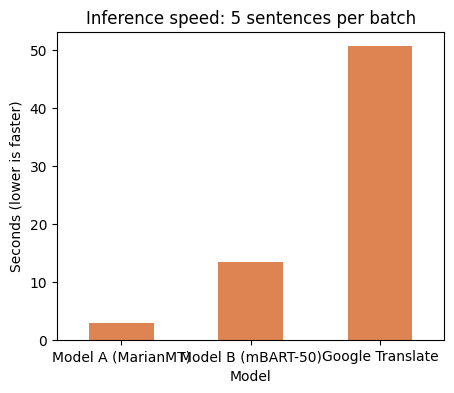

,Avg. seconds per batch
Model,
Model A (MarianMT),2.957
Model B (mBART-50),13.437
Google Translate,50.554


In [ ]:
import time

def time_model(translate_fn, texts, runs=3):
    times = []
    for _ in range(runs):
        start = time.time()
        translate_fn(texts)
        times.append(time.time() - start)
    return sum(times) / len(times)

speed_a = time_model(translate_marian, test_source)
speed_b = time_model(translate_mbart, test_source)
speed_c = time_model(translate_google, test_source)

speed_df = pd.DataFrame({
    "Model": ["Model A (MarianMT)", "Model B (mBART-50)", "Google Translate"],
    "Avg. seconds per batch": [round(speed_a, 3), round(speed_b, 3), round(speed_c, 3)]
}).set_index("Model")

speed_df.plot(kind="bar", legend=False, rot=0, figsize=(5, 4), color="#dd8452")
plt.ylabel("Seconds (lower is faster)")
plt.title("Inference speed: 5 sentences per batch")
plt.show()
speed_df


### Extra: Qualitative Error Inspection

Aggregate scores hide individual mistakes. This prints each source sentence next to
both model outputs and the reference, so errors are visible sentence-by-sentence.


In [ ]:
comparison_df = pd.DataFrame({
    "Source": test_source,
    "Model A (MarianMT)": output_a,
    "Model B (mBART-50)": output_b,
    "Google Translate": output_c,
    "Reference": test_reference
})
comparison_df


,Source,Model A (MarianMT),Model B (mBART-50),Google Translate,Reference
0,The weather is nice today.,मौसम आज अच्छा है.,आज मौसम अच्छा है।,aaj mausam bahut lagta\n hai,आज मौसम अच्छा है।
1,I am learning machine translation.,मैं मशीन अनुवाद सीख रहा हूँ.,मैं मशीन अनुवाद सीख रहा हूँ।,मैं मशीनी अनुवाद सीख रहा हूँ।,मैं मशीन अनुवाद सीख रहा हूँ।
2,Please send me the report by tomorrow.,कृपया मुझे कल से रिपोर्ट भेजें.,कृपया मुझे कल तक रिपोर्ट भेजें।,कृपया मुझे कल तक रिपोर्ट भेजें।,कृपया मुझे कल तक रिपोर्ट भेजें।
3,This city has a long history.,इस शहर का एक लंबा इतिहास है.,इस शहर का इतिहास बहुत पुराना है।,इस शहर का एक लंबा इतिहास रहा है।,इस शहर का एक लंबा इतिहास है।
4,Can you help me with this task?,आप इस कार्य के साथ मेरी मदद कर सकते हैं?,क्या आप इस कार्य में मेरी मदद कर सकते हैं?,क्या आप इस काम में मेरी मदद कर सकते हैं?,क्या आप इस काम में मेरी मदद कर सकते हैं?


## Conclusion

This notebook demonstrated:

- **6 concepts**: text-to-text NMT, image OCR translation, transliteration, language identification, back-translation, and pivot translation
- **2 models + Google Translate reference**: MarianMT (Helsinki-NLP/opus-mt-en-hi), mBART-50 (facebook/mbart-large-50-many-to-many-mmt), and Google Translate as a commercial benchmark
- **6 metrics**: BLEU, chrF, METEOR, TER, WER, and BERTScore
- **Extras**: an inference-speed comparison and a sentence-by-sentence qualitative view

The charts and tables above show which model scores higher, and where each one trades off
quality against speed. For a full evaluation, run this pipeline on a larger, standard test
set (e.g. FLORES-200).
